# 1. Exploring the bookings (weeks 2-4)
**Question:** when do guests cancel, and which cancellations actually cost the hotel money?

For each chart, write one sentence of your own *before* reading the comment under it.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hotel_ob import config, data, model, nights, policy
from hotel_ob.features import make_X
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## The clean table
`scripts/run_pipeline.py` already removed 182 impossible rows and added the label. Look at the columns: which ones does the hotel know **when the guest books**, and which are filled in later?

In [2]:
df = pd.read_parquet(config.PROCESSED_DIR / 'bookings.parquet')
print(df.shape)
df.head(3).T

(119208, 38)


,0,1,2
hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0
lead_time,342,737,7
arrival_date_year,2015,2015,2015
arrival_date_month,July,July,July
arrival_date_week_number,27,27,27
arrival_date_day_of_month,1,1,1
stays_in_weekend_nights,0,0,0
stays_in_week_nights,0,0,1
adults,2,2,1


In [3]:
df.groupby('hotel').agg(bookings=('is_canceled', 'size'), cancel_rate=('is_canceled', 'mean'))

,bookings,cancel_rate
hotel,,
City Hotel,79162,0.418
Resort Hotel,40046,0.278


## 37% cancelled. Should the hotel panic?
A cancellation two months before arrival is not a problem: the room can be sold again. Look at *when* guests cancel.

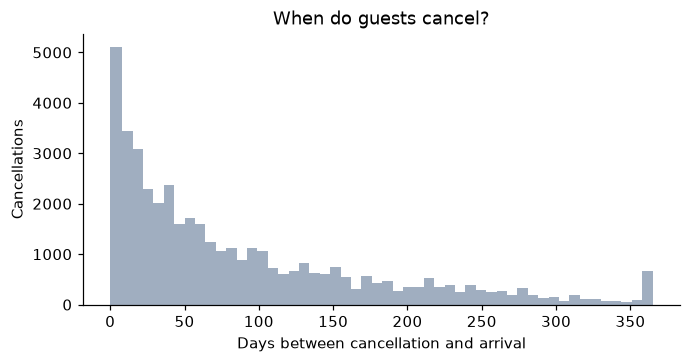

median: 56 days before arrival; within 7 days: 11.9% of cancellations


In [4]:
c = df[df.reservation_status == 'Canceled']
days = c.days_before_cancel.clip(upper=365)
ax = days.plot.hist(bins=np.r_[0, np.arange(8, 367, 7)], color='#a0aec0', figsize=(7, 3.2))
ax.set(xlabel='Days between cancellation and arrival', ylabel='Cancellations', title='When do guests cancel?')
plt.show()
print(f"median: {c.days_before_cancel.median():.0f} days before arrival;",
      f"within 7 days: {(c.days_before_cancel <= 7).mean():.1%} of cancellations")

Only about one cancellation in eight comes in the last week. So the label that matters for overbooking is

> **lost late** = cancelled within 7 days of arrival, *or* a no-show,

measured on bookings that are still on the books 7 days before arrival (`active`), which is when the hotel decides how many rooms to overbook.

In [5]:
df[df.active].groupby('hotel').late.mean().rename('share lost late')

hotel
City Hotel     0.094
Resort Hotel   0.051
Name: share lost late, dtype: float64

## Late losses changed over time

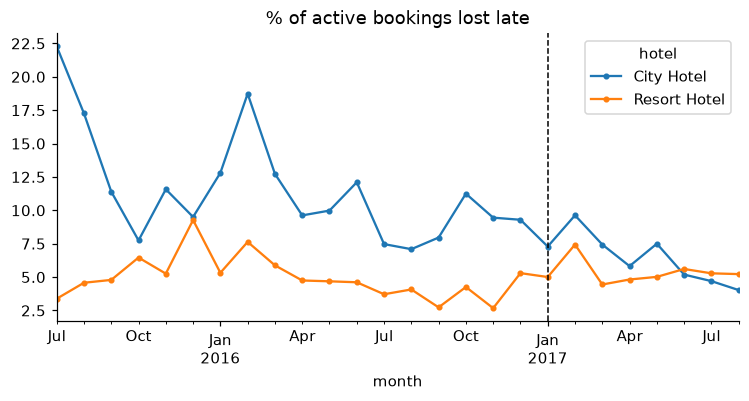

arrival,2015,2016,2017
hotel,,,
City Hotel,0.120,0.105,0.064
Resort Hotel,0.056,0.047,0.054


In [6]:
m = (df[df.active].assign(month=df.arrival.dt.to_period('M').dt.to_timestamp())
       .groupby(['month', 'hotel']).late.mean().unstack())
ax = (m * 100).plot(marker='o', ms=3, figsize=(8, 3.4), title='% of active bookings lost late')
ax.axvline(pd.Timestamp(config.TEST_START), color='black', ls='--', lw=1)
plt.show()
df[df.active].groupby(['hotel', df.arrival.dt.year]).late.mean().unstack()

At the City Hotel the late-loss rate roughly **halved** between 2015 and 2017. Anything trained on the past will expect too many late losses in 2017. Keep this chart in mind: it explains the biggest result of the project (notebook 03).

## A strange category: non-refundable deposits

In [7]:
nr = df[df.deposit_type == 'Non Refund']
print(f"{len(nr):,} non-refundable bookings, {nr.is_canceled.mean():.1%} cancelled, only {(nr.is_canceled == 0).sum()} stayed")
print("median lead time:", nr.lead_time.median(), "days (all bookings:", df.lead_time.median(), ")")
nr.market_segment.value_counts().head()

14,586 non-refundable bookings, 99.4% cancelled, only 93 stayed
median lead time: 183.0 days (all bookings: 69.0 )


market_segment
Groups           9172
Offline TA/TO    5005
Corporate         334
Online TA          56
Direct             19
Name: count, dtype: int64

A non-refundable deposit should make people *less* likely to cancel. Here almost all of them cancelled, mostly groups and travel agents booking about six months ahead. These may be blocks of rooms held by agents, or a recording quirk. We keep the column (it is known at booking time) but treat its effect with suspicion.

### Your turn
1. Which market segment has the highest *late*-loss rate (not cancellation rate)? Is it the same as the highest cancellation rate?
2. Do bookings with special requests get lost late less often? Why might that be?
3. Find one column that you think the hotel only fills in *after* the booking. How could you check?